In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder,OrdinalEncoder,PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.base import clone


In [3]:
df = pd.read_csv("realtor-data.csv")

In [4]:
df.shape

(2226382, 12)

In [5]:
df.head()

,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
0,103378.0,for_sale,105000.0,3.0,2.0,0.12,1962661.0,Adjuntas,Puerto Rico,601.0,920.0,NaN
1,52707.0,for_sale,80000.0,4.0,2.0,0.08,1902874.0,Adjuntas,Puerto Rico,601.0,1527.0,NaN
2,103379.0,for_sale,67000.0,2.0,1.0,0.15,1404990.0,Juana Diaz,Puerto Rico,795.0,748.0,NaN
3,31239.0,for_sale,145000.0,4.0,2.0,0.10,1947675.0,Ponce,Puerto Rico,731.0,1800.0,NaN
4,34632.0,for_sale,65000.0,6.0,2.0,0.05,331151.0,Mayaguez,Puerto Rico,680.0,NaN,NaN


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2226382 entries, 0 to 2226381
Data columns (total 12 columns):
 #   Column          Dtype  
---  ------          -----  
 0   brokered_by     float64
 1   status          str    
 2   price           float64
 3   bed             float64
 4   bath            float64
 5   acre_lot        float64
 6   street          float64
 7   city            str    
 8   state           str    
 9   zip_code        float64
 10  house_size      float64
 11  prev_sold_date  str    
dtypes: float64(8), str(4)
memory usage: 203.8 MB


In [9]:
print("Null values: \n",df.isnull().sum())
print("Duplicate instances: ", df.duplicated().sum())

Null values: 
 brokered_by         4533
status                 0
price               1541
bed               481317
bath              511771
acre_lot          325589
street             10866
city                1407
state                  8
zip_code             299
house_size        568484
prev_sold_date    734297
dtype: int64
Duplicate instances:  0


In [15]:
X = df.drop("price",axis = 1)
y = df["price"]

In [ ]:
Numerical_Features = 

In [ ]:
df.select_dtypes(include = "number").corr()

,brokered_by,price,bed,bath,acre_lot,street,zip_code,house_size
brokered_by,1.000000,-0.006318,0.003588,-0.004113,0.000150,0.000949,0.063217,-0.000522
price,-0.006318,1.000000,0.114761,0.178391,0.016166,-0.017832,0.038672,0.000254
bed,0.003588,0.114761,1.000000,0.611708,-0.000021,-0.000124,0.002519,0.189682
bath,-0.004113,0.178391,0.611708,1.000000,-0.000962,0.000190,0.003687,0.223767
acre_lot,0.000150,0.016166,-0.000021,-0.000962,1.000000,0.002282,-0.002249,0.000987
street,0.000949,-0.017832,-0.000124,0.000190,0.002282,1.000000,-0.001219,0.000314
zip_code,0.063217,0.038672,0.002519,0.003687,-0.002249,-0.001219,1.000000,0.000879
house_size,-0.000522,0.000254,0.189682,0.223767,0.000987,0.000314,0.000879,1.000000


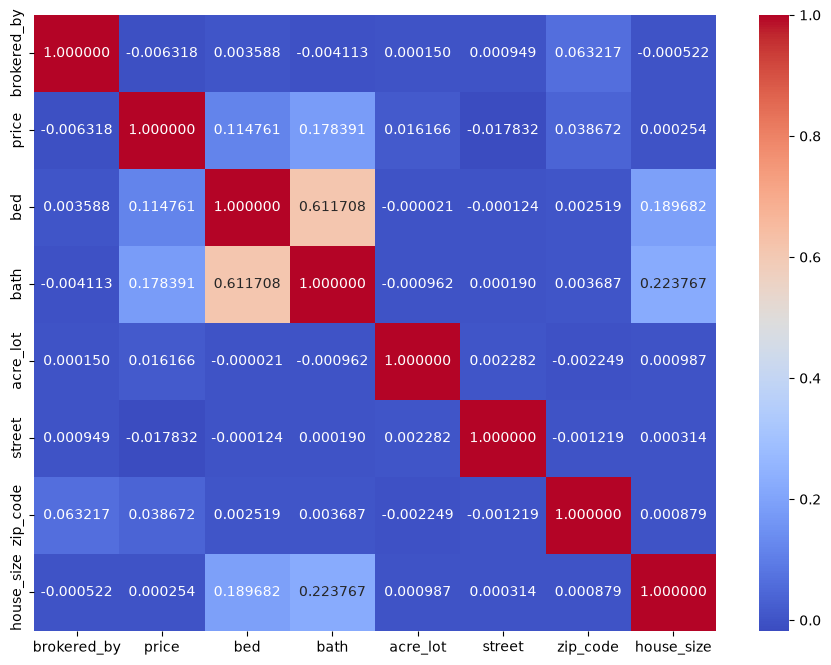

In [17]:
plt.figure(figsize = (11,8))
sns.heatmap(df.select_dtypes(include = "number").corr(), annot = True, cmap = "coolwarm", fmt = ".6f")
plt.show()